# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [4]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv ('/datasets/usage.csv')

In [5]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
users.head() # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [7]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
plans.info() # inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
users.info() # inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
usage.info() # inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:
print("Cantidad de valores nulos",users.isna().sum())
print("Proporción de valores nulos",users.isna().sum()/len(users))

Cantidad de valores nulos user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
print("Cantidad de valores nulos",usage.isna().sum())
print("Proporción de valores nulos",usage.isna().sum()/len(usage))

Cantidad de valores nulos id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: 
Valores nulos
- users.city: 469 nulos (11.7%). Investigar; dejar como nulo y revisar los valores "?", porque eliminar filas haría perder clientes.
- users.churn_date: 3534 nulos (88.4%). Ignorar; el nulo significa que el cliente sigue activo, no es un dato perdido.
- usage.date: 50 nulos (0.125%). Dejar como nulos (o eliminar esas filas); son muy pocas.
- usage.duration: 22076 nulos (55.2%). Ignorar; solo las llamadas tienen duración.
- usage.length: 17896 nulos (44.7%). Ignorar; solo los mensajes tienen longitud.

plans no tiene valores nulos.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
users.describe() # explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`: Es un identificador y no se interpreta como una magnitud.No hay observaciones al respecto. Puede ser trabajada tal y como está.

- La columna 'age': el mínimo de −999 es el sentinel, imposible para una edad. Hay dos señales más en la misma tabla que lo confirman:
La media es 33.7, pero la mediana (50%) es 47. Una media tan por debajo de la mediana indica que unos valores muy bajos la están arrastrando.
La desviación estándar es 123, desproporcionada para edades que en los cuartiles van de 32 a 63.
El máximo, 79, sí es razonable.

In [15]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`: son identificadores y no se interpretan como magnitudes. No hay observaciones al respecto por lo que no hay correcciones que hacer.

- Las columnas `duration` y `length`: el mínimo de ambas es 0, un valor sospechoso. Una llamada de duración 0 o un mensaje de longitud 0 resultan poco creíbles. Conviene revisar cuántas filas tienen ese valor antes de decidir qué hacer con ellas.

In [16]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())


          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city`: confirma que le faltan datos. Tiene 3531 valores de 4000, lo que coincide con los 469 nulos detectados en el paso anterior, que hay que resolver. Tiene 7 ciudades distintas, y Bogotá es la más frecuente (808 registros), por lo que en principio sería la ciudad con más usuarios. El "?" visto en las primeras filas puede estar entre las 7, así que conviene revisarlo.

- La columna `plan`: está correcta. Tiene 4000 datos y solo 2 valores distintos, que corresponden a los dos planes del archivo `plans`: Basico y Premium. Basico es el más frecuente (2595 de 4000), por lo que parece ser el plan más popular entre los usuarios.

In [17]:
# explorar columna categórica de usage
print(usage['type'].describe())

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object


- La columna `type`: no tiene datos faltantes (40000 de 40000) y tiene 2 valores distintos, call y text. El más frecuente es text (22092 registros). No se ven valores raros. Los conteos sugieren unos pocos registros donde una llamada tiene length o un mensaje tiene duration, lo que conviene revisar más adelante.


---
✍️ **Comentario**

**Valores inválidos o sentinels**  
- users.age: contiene el sentinel -999 (el mínimo del resumen estadístico), imposible para una edad. Acción: reemplazarlo por nulo y luego imputarlo con la mediana, porque el -999 distorsiona la media y la desviación.
- users.city: contiene el valor "?", visto en las primeras filas, que no se detecta como nulo. Acción: reemplazarlo por nulo y tratarlo junto con los 469 nulos de la columna.
- usage.duration y usage.length: tienen mínimo 0, un valor sospechoso. Acción: contar cuántas filas tienen 0 y decidir después; si son pocas, tratarlas como nulos.
- usage.type, duration y length: hay unos 28 registros con ambos valores llenos (llamadas con length o mensajes con duration). Acción: revisarlos y dejar solo el valor que corresponde al tipo.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [18]:
users['reg_date'] = pd.to_datetime(users['reg_date'],errors = 'coerce')

In [19]:
usage['date'] = pd.to_datetime(usage['date'],errors = 'coerce')

In [20]:
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, el formato es correcto: todos los registros se convirtieron a fecha. Los años son 2022 (1314), 2023 (1316), 2024 (1330) y 2026 (40). El año 2026 es imposible, porque los datos llegan solo hasta 2024, y es un error de captura. Acción: tratar esas 40 fechas (1% del total) como inválidas, convertirlas en nulas y excluirlas del análisis por fecha, sin eliminar a los clientes para no perder información valiosa que altere los indicadores

In [21]:
print(usage['date'].dt.year.value_counts().sort_index())

2024.0    39950
Name: date, dtype: int64


En `date`, En date, el formato es correcto: la conversión a fecha funcionó. Todos los registros con fecha son del año 2024 (39950 de 40000; los 50 restantes son los nulos ya detectados). No hay años futuros ni negativos, por lo que no se detectan fechas imposibles. Sin embargo, mientras users tiene registros de 2022, 2023 y 2024 (más 40 de 2026, que son un error), usage solo contiene 2024. Por eso el análisis de uso se limita a ese año, aunque haya clientes registrados desde 2022.

✍️ **Comentario**: 
- users.reg_date: Aparecen años imposibles. Hay 40 registros del año 2026 (1% del total), cuando los datos llegan solo hasta 2024. La acción recomendada: tratar esas fechas como inválidas, convertirlas en nulas y excluirlas del análisis por fecha, sin eliminar a los clientes.
- usage.date: No aparecen años imposibles. Todos los registros con fecha son de 2024. La acción recomendada: ninguna sobre los años; los 50 nulos ya detectados se manejan aparte.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [22]:

# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace(-999, np.nan)
age_mediana = users['age'].median() 
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [23]:
# Reemplazar ? por NA en city
users['city']=users['city'].replace ("?",pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [24]:
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

print(users['reg_date'].dt.year.value_counts().sort_index())


2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [26]:
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Diagnóstico de nulos en duration y length

Los nulos de ambas columnas son MAR: dependen de la columna type. En duration, la proporción de nulos es 0% en las llamadas (call) y 99.93% en los mensajes (text). En length ocurre lo contrario: 99.93% de nulos en las llamadas y 0% en los mensajes. Es decir, cada columna solo tiene sentido para uno de los dos tipos de evento.

Decisión: dejarlos como nulos. Imputarlos inventaría duraciones para mensajes y longitudes para llamadas, que no existen. Los pocos registros que rompen la regla (unas 12 llamadas con length y 16 mensajes con duration) conviene revisarlos aparte.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id")[["is_text", "is_call", "duration"]].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
usage_agg =usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
print(user_profile[['cant_mensajes','cant_llamadas','cant_minutos_llamada','age']].describe())


       cant_mensajes  cant_llamadas  cant_minutos_llamada          age
count    3999.000000    3999.000000           3999.000000  4000.000000
mean        5.524381       4.478120             23.317054    48.136000
std         2.358416       2.144238             18.168095    17.689919
min         0.000000       0.000000              0.000000    18.000000
25%         4.000000       3.000000             11.120000    33.000000
50%         5.000000       4.000000             19.780000    48.000000
75%         7.000000       6.000000             31.415000    63.000000
max        17.000000      15.000000            155.690000    79.000000


In [31]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True)*100)


Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

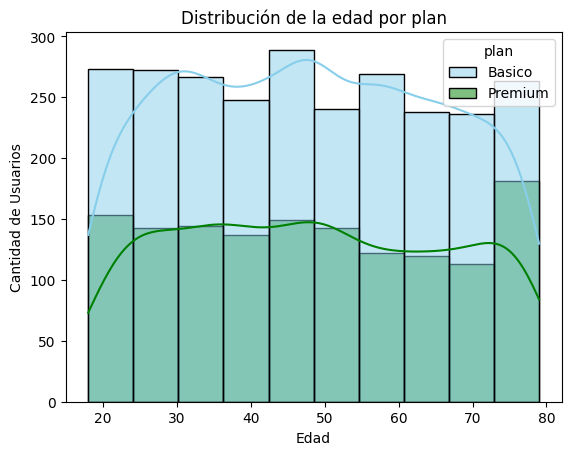

In [32]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.xlabel('Edad')
plt.ylabel ('Cantidad de Usuarios')
plt.title ('Distribución de la edad por plan')
plt.show()

💡Insights: La edad de los usuarios se distribuye de forma bastante uniforme entre los 18 y los 79 años, sin concentración en una edad. Ambos planes siguen esa misma forma, aunque el plan Básico tiene más usuarios en todos los rangos. No se observan valores atípicos

Text(0.5, 1.0, 'Distribución de la cantidad de mensajes por plan')

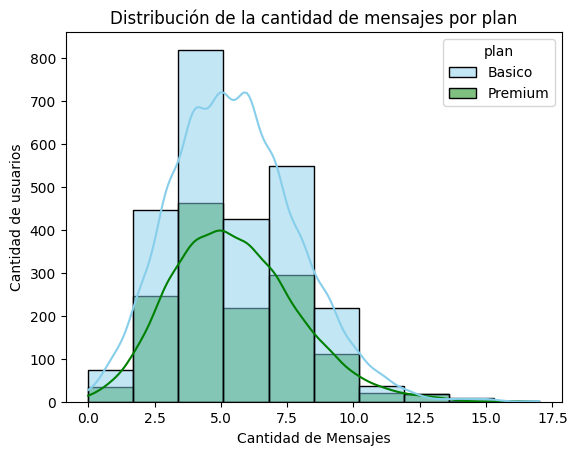

In [34]:
sns.histplot(data=user_profile, x='cant_mensajes', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de la cantidad de mensajes por plan')

💡Insights: 
La mayoría de los usuarios envía entre 3 y 8 mensajes, con un pico alrededor de 5. La distribución está sesgada a la derecha: pocos usuarios envían más de 12 mensajes. Ambos planes muestran la misma forma, y el Básico tiene más usuarios en todos los rangos. No se observa una diferencia de comportamiento entre planes

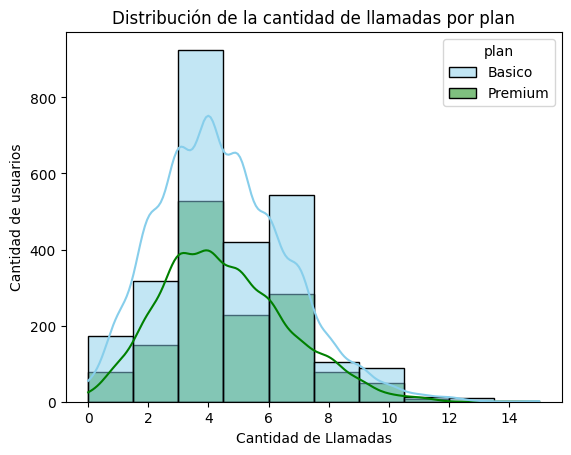

In [35]:
sns.histplot(data=user_profile, x='cant_llamadas', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de la cantidad de llamadas por plan')
plt.show()

💡Insights: 
La mayoría de los usuarios realiza entre 2 y 7 llamadas, con un pico alrededor de 4. La distribución está sesgada a la derecha, con pocos usuarios que superan las 10 llamadas. Los dos planes siguen la misma forma, y el Básico tiene más usuarios en todos los rangos

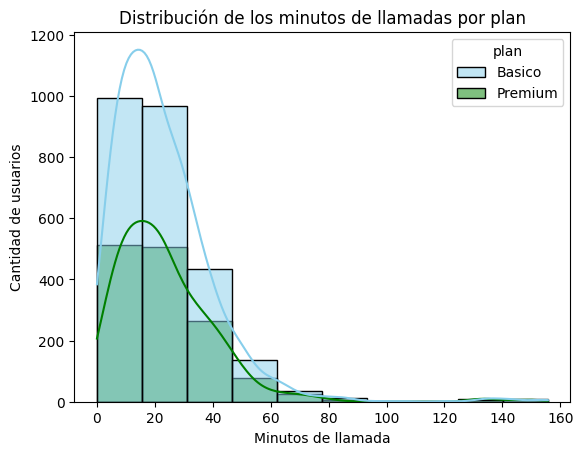

In [36]:
sns.histplot(data=user_profile, x='cant_minutos_llamada', bins=10, hue='plan', palette=['skyblue','green'], kde=True)
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de los minutos de llamadas por plan')
plt.show()

💡Insights: 
La mayoría de los usuarios acumula menos de 45 minutos de llamada, con un pico entre 0 y 30. La distribución está fuertemente sesgada a la derecha: unos pocos usuarios superan los 120 minutos, lo que eleva la media (23.3) por encima de la mediana (19.8). Ambos planes tienen la misma forma. Estos valores altos son posibles atípicos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

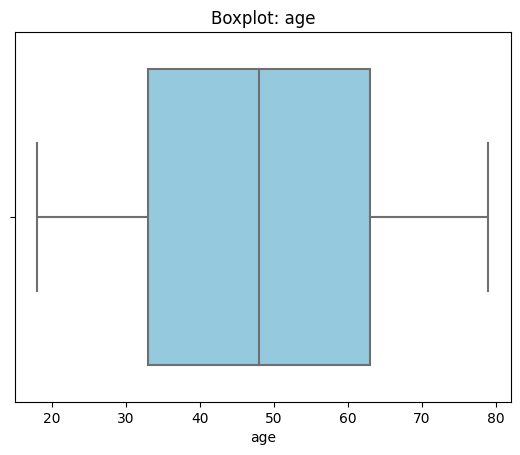

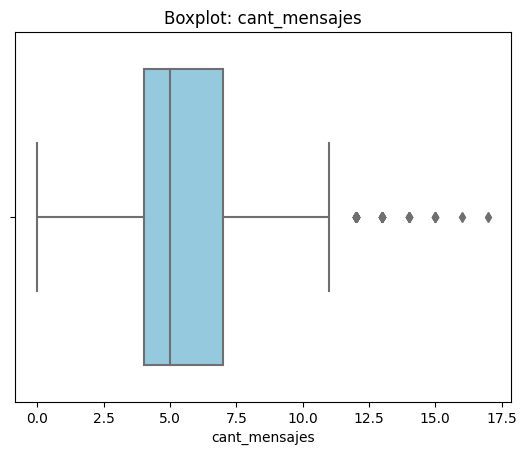

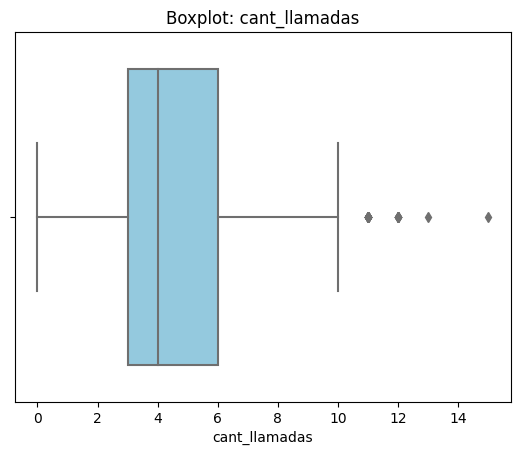

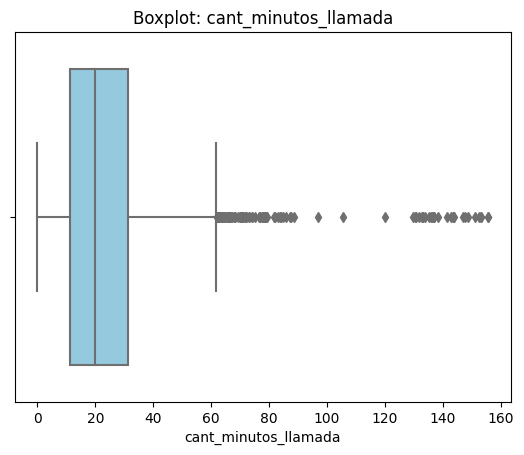

In [37]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: no presenta outliers. La caja y los bigotes cubren de 18 a 79, sin puntos sueltos.
- cant_mensajes: sí presenta outliers, solo del lado derecho, desde 12 hasta 17 mensajes.
- cant_llamadas: sí presenta outliers, solo del lado derecho, desde 11 hasta 15 llamadas.
- cant_minutos_llamada: sí presenta muchos outliers, solo del lado derecho. Empiezan cerca de 62 minutos y llegan hasta unos 155, con un grupo alejado entre 130 y 155

In [39]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    cantidad = (user_profile[col] > limite_superior).sum()
    print(col, '| límite superior:', limite_superior, '| usuarios por encima:', cantidad)

cant_mensajes | límite superior: 11.5 | usuarios por encima: 46
cant_llamadas | límite superior: 10.5 | usuarios por encima: 30
cant_minutos_llamada | límite superior: 61.8575 | usuarios por encima: 109


In [40]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener. El límite superior es 11.5 y el máximo es 17. Son 46 usuarios (1.2%), con valores posibles para un usuario muy activo. No son errores, y quitarlos haría perder información de los clientes que más escriben.
- cant_llamadas: mantener. El límite superior es 10.5 y el máximo es 15. Son 30 usuarios (0.8%), una cantidad razonable de llamadas. No hay valores imposibles.
- cant_minutos_llamada: mantener. El límite superior es 61.86 minutos y el máximo es 155.69. Son 109 usuarios (2.7%). Aunque la cola es larga, 155 minutos es un uso plausible y corresponde a usuarios de uso intensivo. Se conservan, y para resumir esta columna conviene apoyarse en la mediana (19.78) porque la media (23.32) sube por estos valores altos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
user_profile[['cant_llamadas', 'cant_mensajes']].dtypes

cant_llamadas    float64
cant_mensajes    float64
dtype: object

In [44]:
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] <5) & (user_profile['cant_mensajes'] <5), 'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] <10) & (user_profile['cant_mensajes'] <10), 'Uso medio',
        'Alto uso'))



In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [46]:
user_profile['grupo_edad'] = np.where(
    user_profile['age'] <30, 'Joven',
    np.where(
        user_profile['age'] <60, 'Adulto',
        'Adulto Mayor'))


In [47]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

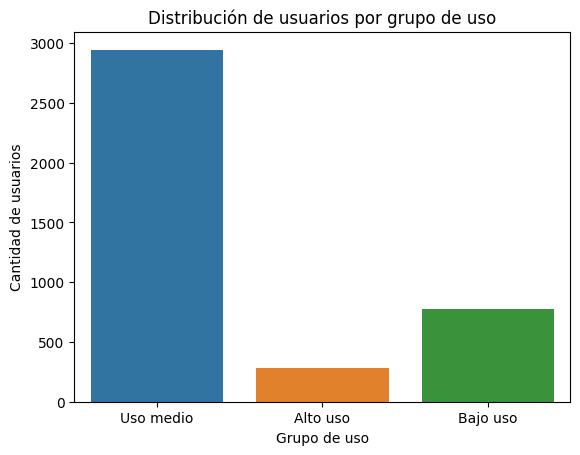

In [48]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de uso')
plt.show()

plt.show()

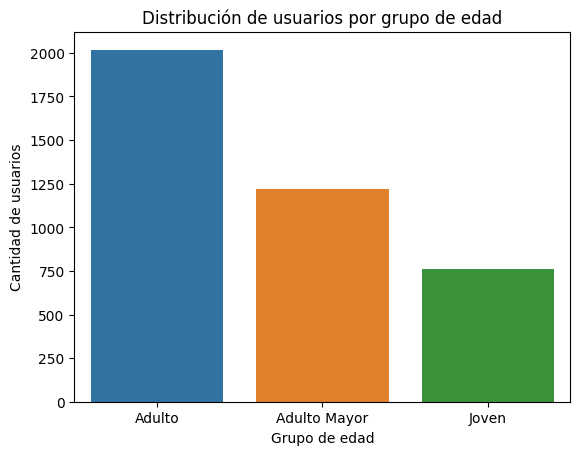

In [49]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Edad con valor centinela -999 (código de dato faltante, no una edad real): se reemplazó por la mediana.
- Ciudad con “?” como marcador de dato desconocido: se convirtió en nulo.
40 fechas de registro en 2026 (1% de 3.999 usuarios), posteriores al periodo analizado: se marcaron como fecha nula.
- Nulos en duración y longitud de las interacciones: dependen del tipo (llamada o mensaje), por lo que no son errores. churn_date vacío significa cliente activo.

🔍 **Segmentos por Edad**
- Adultos (30 a 59 años): 50% de los usuarios, el segmento más grande.
- Adultos mayores (60 o más): 31%.
- Jóvenes (menos de 30): 19%, la minoría.
- Las edades van de 18 a 79 y se reparten de forma uniforme.

📊 **Segmentos por Nivel de Uso**
- Uso medio: 74% de los usuarios, el grupo dominante.
- Bajo uso: 19%.
- Alto uso: 7%, el grupo más pequeño.
- Hay outliers solo en el extremo superior: mensajes (46 usuarios), llamadas (30) y minutos de llamada (109, hasta 155.7 minutos). Se conservaron porque son usuarios intensivos, no errores.

➡️ Esto sugiere que la base de clientes se concentra en un uso moderado, con adultos como segmento principal. Los usuarios de alto uso son pocos pero estratégicos, y ambos planes (Básico 65%, Premium 35%) se usan igual, lo que indica que Premium todavía no muestra un valor diferencial claro.

💡 **Recomendaciones**
Crear un plan con más minutos y mensajes para los usuarios de alto uso y los que superan los límites típicos.
Retener al 19% de bajo uso con un plan de entrada más económico o incentivos de uso.
Reforzar el valor de Premium y ofrecer pruebas a usuarios Básico con uso alto.
Diseñar ofertas por edad: paquetes para adultos (el mayor grupo) y planes simples de llamadas para adultos mayores.
Evitar valores centinela (-999 y “?”) en el registro de datos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`